In [ ]:

from google.colab import files

uploaded = files.upload()

Saving ecommerce_sales_data-1.csv to ecommerce_sales_data-1.csv


In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 15

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully!
Rows and columns: (100, 12)


,Order ID,Customer ID,Gender,Age,Product Category,Product Name,Quantity,Price,Order Date,Payment Method,City,Rating
0,ORD0001,CUST9376,Female,43,Home,Lamp,1,1368.69,07-06-2025,Cash on Delivery,Hyderabad,3
1,ORD0002,CUST3289,Male,57,Toys,Lego Set,5,782.44,11-12-2024,Cash on Delivery,Chennai,5
2,ORD0003,CUST6409,Female,53,Clothing,Jacket,1,3676.18,05-05-2025,Credit Card,Bangalore,4
3,ORD0004,CUST8815,Female,51,Beauty,Perfume,2,4836.37,25-06-2025,Cash on Delivery,Mumbai,5
4,ORD0005,CUST1018,Female,39,Electronics,Smartphone,4,3580.24,25-12-2024,UPI,Kolkata,3


In [ ]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['Order ID', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Product Name', 'Quantity', 'Price', 'Order Date', 'Payment Method', 'City', 'Rating']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order ID          100 non-null    object 
 1   Customer ID       100 non-null    object 
 2   Gender            100 non-null    object 
 3   Age               100 non-null    int64  
 4   Product Category  100 non-null    object 
 5   Product Name      100 non-null    object 
 6   Quantity          100 non-null    int64  
 7   Price             100 non-null    float64
 8   Order Date        100 non-null    object 
 9   Payment Method    100 non-null    object 
 10  City              100 non-null    object 
 11  Rating            100 non-null    int64  
dtypes: float64(1), int64(3), object(8)
memory usa

,0
Order ID,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Product Name,0
Quantity,0
Price,0
Order Date,0
Payment Method,0



Duplicate rows: 0


In [ ]:

df["Order Date"] = pd.to_datetime(
    df["Order Date"], dayfirst=True, errors="coerce"
)

for col in ["Age", "Quantity", "Price", "Rating"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Sales"] = df["Quantity"] * df["Price"]

df["Month"] = df["Order Date"].dt.to_period("M").astype(str)

df["Quarter"] = (
    df["Order Date"].dt.year.astype("Int64").astype(str)
    + "-Q"
    + df["Order Date"].dt.quarter.astype("Int64").astype(str)
)

print("Data preparation completed!")
print("Date range:", df["Order Date"].min(), "to", df["Order Date"].max())
print("Total calculated sales:", round(df["Sales"].sum(), 2))

display(df.head())

Data preparation completed!
Date range: 2024-07-15 00:00:00 to 2025-07-06 00:00:00
Total calculated sales: 694219.87


,Order ID,Customer ID,Gender,Age,Product Category,Product Name,Quantity,Price,Order Date,Payment Method,City,Rating,Sales,Month,Quarter
0,ORD0001,CUST9376,Female,43,Home,Lamp,1,1368.69,2025-06-07,Cash on Delivery,Hyderabad,3,1368.69,2025-06,2025-Q2
1,ORD0002,CUST3289,Male,57,Toys,Lego Set,5,782.44,2024-12-11,Cash on Delivery,Chennai,5,3912.20,2024-12,2024-Q4
2,ORD0003,CUST6409,Female,53,Clothing,Jacket,1,3676.18,2025-05-05,Credit Card,Bangalore,4,3676.18,2025-05,2025-Q2
3,ORD0004,CUST8815,Female,51,Beauty,Perfume,2,4836.37,2025-06-25,Cash on Delivery,Mumbai,5,9672.74,2025-06,2025-Q2
4,ORD0005,CUST1018,Female,39,Electronics,Smartphone,4,3580.24,2024-12-25,UPI,Kolkata,3,14320.96,2024-12,2024-Q4


In [ ]:

numeric_cols = ["Age", "Quantity", "Price", "Rating", "Sales"]

stats = df[numeric_cols].describe().round(2)

# Age ke column mein decimals hatao
stats["Age"] = stats["Age"].round(0).astype("Int64")

print("Descriptive Statistics")
display(stats)

print("Mean")
mean_values = df[numeric_cols].mean().round(2)
mean_values["Age"] = round(mean_values["Age"])
display(mean_values)

print("Median")
median_values = df[numeric_cols].median().round(2)
median_values["Age"] = round(median_values["Age"])
display(median_values)

print("Mode")
mode_values = df[numeric_cols].mode().iloc[0].round(2)
mode_values["Age"] = round(mode_values["Age"])
display(mode_values)

print("Standard Deviation")
std_values = df[numeric_cols].std().round(2)
std_values["Age"] = round(std_values["Age"])
display(std_values)

Descriptive Statistics


,Age,Quantity,Price,Rating,Sales
count,100,100.00,100.00,100.00,100.00
mean,38,2.94,2428.30,3.00,6942.20
std,12,1.44,1508.12,1.39,5883.72
min,18,1.00,118.33,1.00,295.10
25%,28,2.00,1130.62,2.00,2494.13
50%,38,3.00,2160.36,3.00,4901.68
75%,49,4.00,3743.87,4.00,9472.98
max,60,5.00,4836.37,5.00,23279.10


Mean


,0
Age,38.00
Quantity,2.94
Price,2428.30
Rating,3.00
Sales,6942.20


Median


,0
Age,38.00
Quantity,3.00
Price,2160.36
Rating,3.00
Sales,4901.68


Mode


,0
Age,23.00
Quantity,1.00
Price,118.33
Rating,3.00
Sales,295.10


Standard Deviation


,0
Age,12.00
Quantity,1.44
Price,1508.12
Rating,1.39
Sales,5883.72



## Descriptive Statistics

Mean, median, mode, and standard deviation were calculated to summarize the numerical variables and understand their distribution and variability.

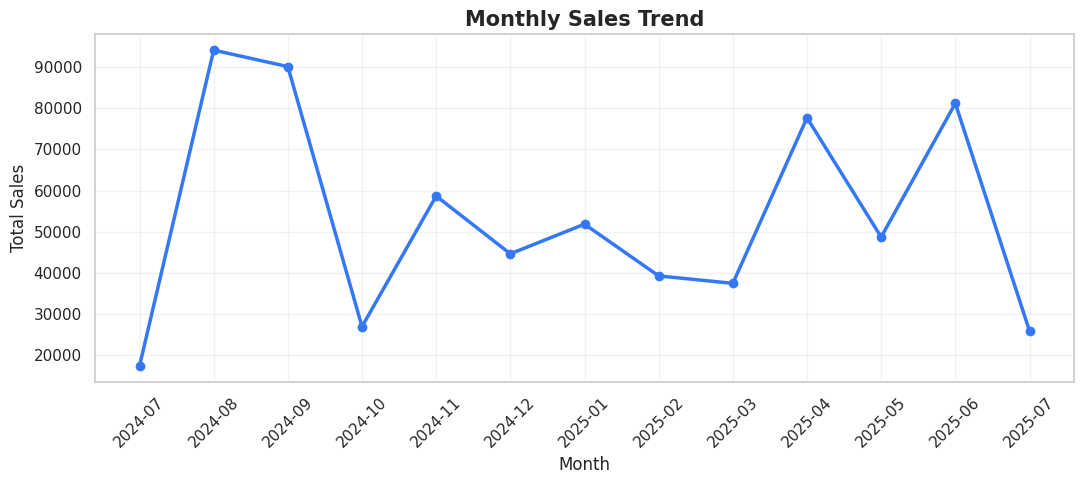

,Sales
Month,
2024-07,17411.29
2024-08,94121.76
2024-09,90122.59
2024-10,26986.55
2024-11,58692.98
2024-12,44666.03
2025-01,51865.59
2025-02,39294.12
2025-03,37495.60


In [ ]:

monthly_sales = df.groupby("Month")["Sales"].sum().sort_index()

plt.figure(figsize=(11, 5))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    color="#3478F6",
    marker="o",
    linewidth=2.5
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

display(monthly_sales)

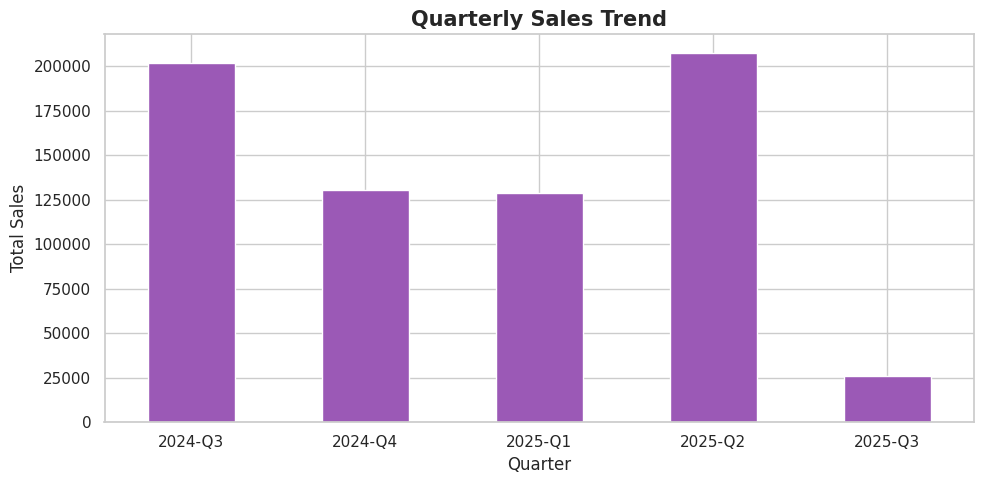

,Sales
Quarter,
2024-Q3,201655.64
2024-Q4,130345.56
2025-Q1,128655.31
2025-Q2,207629.26
2025-Q3,25934.10


In [ ]:

quarterly_sales = df.groupby("Quarter")["Sales"].sum().sort_index()

plt.figure(figsize=(10, 5))
quarterly_sales.plot(kind="bar", color="#9B59B6")

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(quarterly_sales)

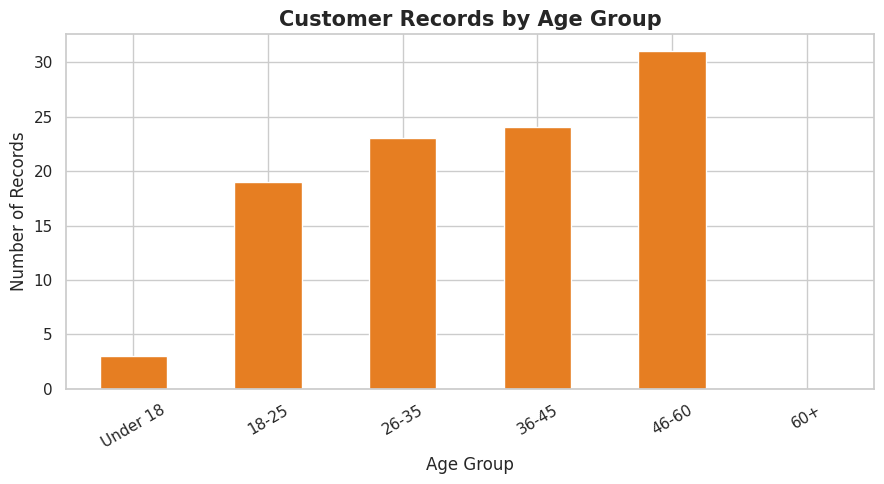

,count
Age Group,
Under 18,3
18-25,19
26-35,23
36-45,24
46-60,31
60+,0


In [ ]:

df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 18, 25, 35, 45, 60, 100],
    labels=["Under 18", "18-25", "26-35", "36-45", "46-60", "60+"],
    include_lowest=True
)

age_counts = df["Age Group"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
age_counts.plot(kind="bar", color="#E67E22")

plt.title("Customer Records by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(age_counts)

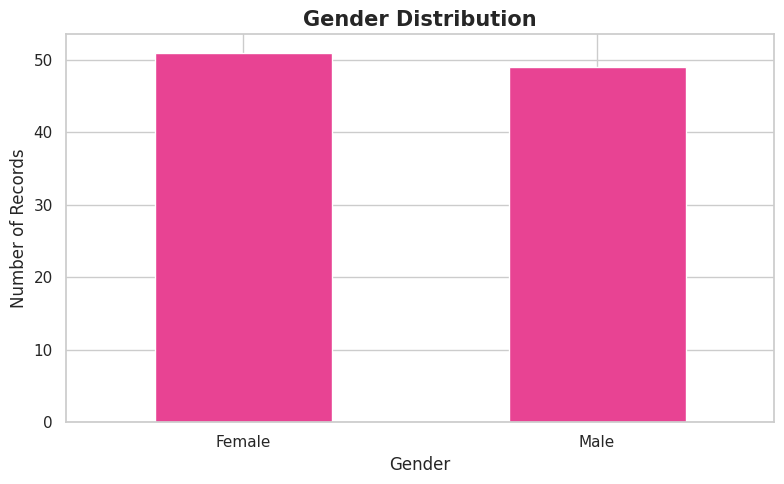

,count
Gender,
Female,51
Male,49


In [ ]:

gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(8, 5))
gender_counts.plot(kind="bar", color="#E84393")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(gender_counts)

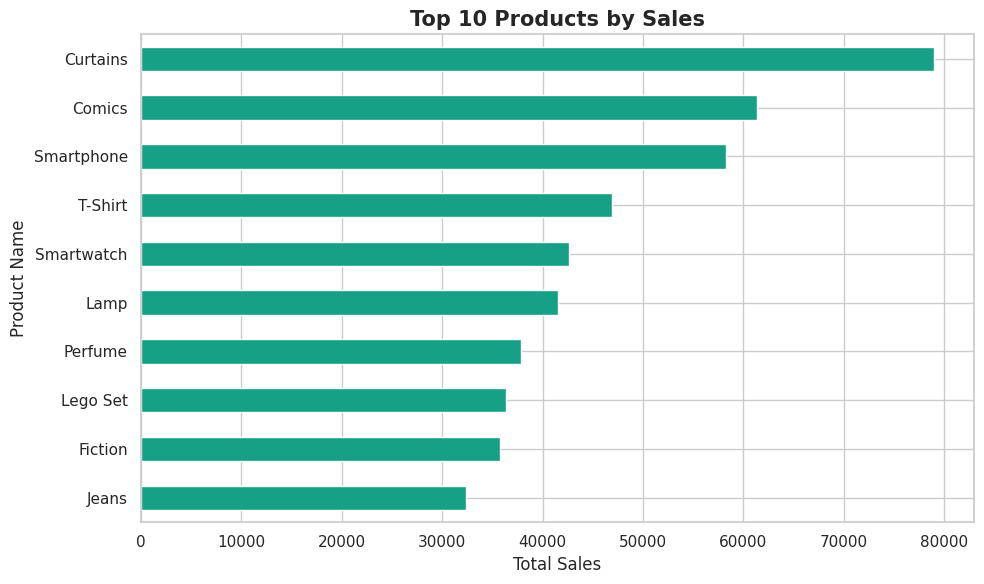

,Sales
Product Name,
Curtains,79023.10
Comics,61394.03
Smartphone,58226.56
T-Shirt,46895.37
Smartwatch,42657.05
Lamp,41530.60
Perfume,37875.85
Lego Set,36345.05
Fiction,35729.68


In [ ]:

top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh", color="#16A085")

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

display(top_products)

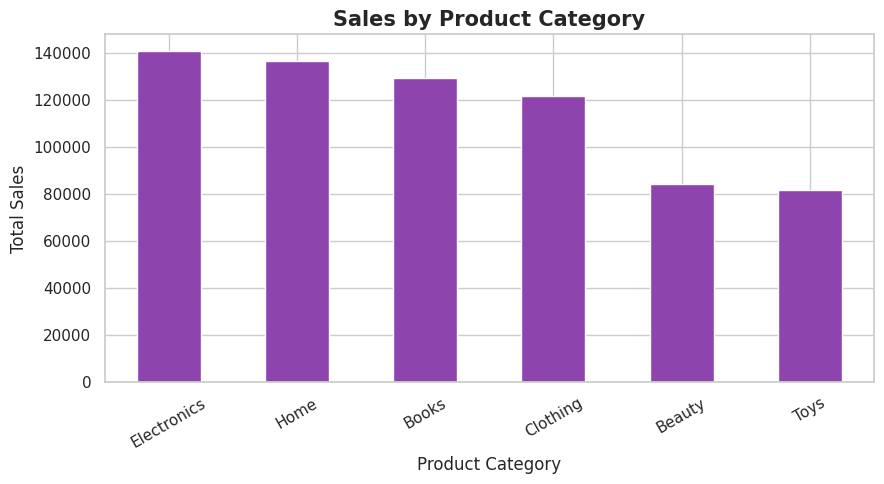

,Sales
Product Category,
Electronics,140811.26
Home,136365.47
Books,129177.30
Clothing,121504.99
Beauty,84457.92
Toys,81902.93


In [ ]:

category_sales = (
    df.groupby("Product Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
category_sales.plot(kind="bar", color="#8E44AD")

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(category_sales)

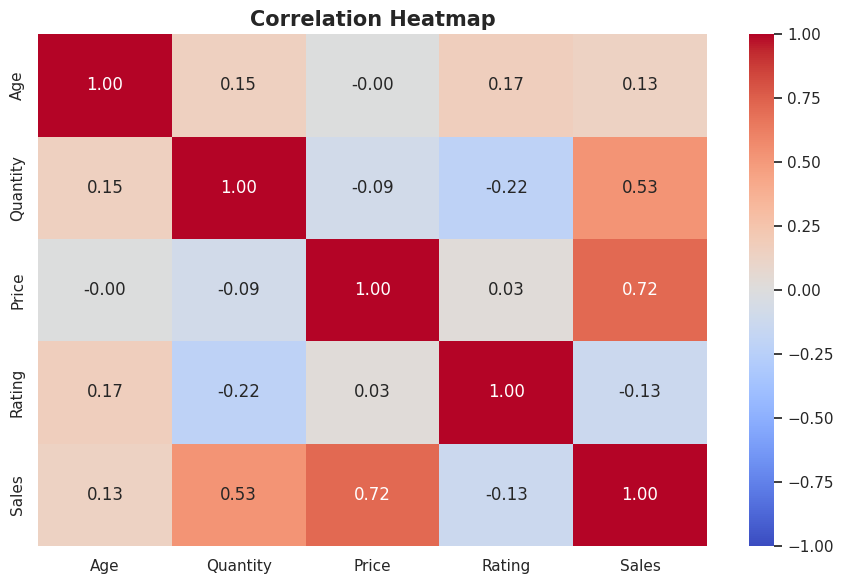

In [ ]:

numeric_cols = ["Age", "Quantity", "Price", "Rating", "Sales"]

plt.figure(figsize=(9, 6))
sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

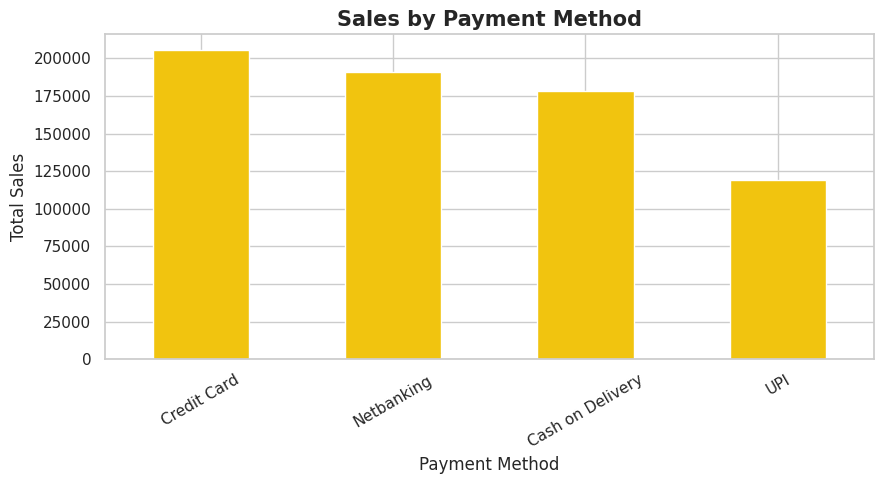

,Sales
Payment Method,
Credit Card,205724.70
Netbanking,190707.30
Cash on Delivery,178313.61
UPI,119474.26


In [ ]:

payment_sales = (
    df.groupby("Payment Method")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
payment_sales.plot(kind="bar", color="#F1C40F")

plt.title("Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(payment_sales)


## Business Recommendations

1. **Product Optimization:** Focus on products with strong sales and investigate weaker-performing products before changing inventory.

2. **Customer Targeting:** Use the age-group and gender distributions to guide customer research and marketing campaigns without making unsupported assumptions.

3. **Sales Planning:** Compare monthly and quarterly sales patterns to support inventory planning and promotional decisions.


## Conclusion

This exploratory data analysis examined sales trends, customer demographics, product performance, category-wise sales, numerical correlations, and payment methods.

The findings can help identify opportunities for product promotion, customer analysis, and sales planning. However, the dataset contains only 100 records, so results should be interpreted within the limits of this sample.

Sales values were calculated by multiplying Quantity by Price. This assumes Price is the unit price and does not account for discounts, refunds, or taxes that are not recorded in the dataset.